# 01 — Text Preprocessing, EDA & Subword Tokenization
**Proyek: Agentic Campus — Klasifikasi Topik Skripsi Teknik Informatika**  
**Mata Kuliah: Natural Language Processing**

Notebook ini menjalankan tahap preprocessing teks sebelum pemodelan. Tujuannya sederhana: mengubah teks judul dan abstrak skripsi yang masih kotor menjadi representasi kata bersih yang siap digunakan model.

Urutan langkah yang dikerjakan:
1. **Load data & gabung kolom** — Judul dan Abstrak digabung menjadi satu kolom teks per dokumen.
2. **Normalisasi typo** — Koreksi salah ketik istilah teknis seperti `algortima`, `blackchain`, `platfrom`, dll.
3. **Pipeline pembersihan** — Case folding, hapus angka & tanda baca, tokenisasi NLTK, hapus stopword.
4. **Simpan data bersih** — Hasil disimpan ke `data/processed/data_clean.csv` untuk dipakai di notebook berikutnya.
5. **EDA & Visualisasi** — WordCloud sebelum vs sesudah, frekuensi kata, distribusi kelas.
6. **WordPiece Tokenization** — Eksplorasi tokenisasi subword berbasis BERT dan kalkulasi rasio kompresi.


## 0. Import Library & Persiapan Lingkungan


In [17]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.tokenize import word_tokenize
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from transformers import BertTokenizer

# Pastikan resource NLTK tokenizer telah terunduh
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Konfigurasi visualisasi & pandas
pd.set_option('display.max_colwidth', 200)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Seluruh pustaka NLP, Visualisasi, dan Tokenizer berhasil dimuat.")


Seluruh pustaka NLP, Visualisasi, dan Tokenizer berhasil dimuat.


## 1. Load Dataset Korpus Skripsi & Penggabungan Kolom
Dataset mentah (`data_gabungan.csv`) berisi 1.136 dokumen judul dan abstrak skripsi mahasiswa Teknik Informatika. Kolom `Judul` dan `Abstrak` digabung menjadi satu kolom `teks_lengkap` supaya setiap dokumen memiliki konteks yang lebih kaya sebelum dibersihkan.


In [18]:
RAW_PATH = "../data/raw/data_gabungan.csv"
df = pd.read_csv(RAW_PATH)

# Handle missing values sebelum konkatenasi
df["Judul"] = df["Judul"].fillna("")
df["Abstrak"] = df["Abstrak"].fillna("")

# Gabungkan Judul dan Abstrak
df["teks_lengkap"] = df["Judul"].str.strip() + " " + df["Abstrak"].str.strip()

print(f"Total dokumen: {len(df)}")
print(f"Jumlah dokumen dengan label kelas: {df['Kelas'].notna().sum()}")
df[["No", "Judul", "Kelas", "teks_lengkap"]].head(3)


Total dokumen: 1136
Jumlah dokumen dengan label kelas: 200


,No,Judul,Kelas,teks_lengkap
0,1,Klasifikasi kecenderungan Tingkat Depresi Mahasiswa menggunakan Learning Vector Quantization 3,1.0,Klasifikasi kecenderungan Tingkat Depresi Mahasiswa menggunakan Learning Vector Quantization 3 Depresi merupakan masalah kondisi kesehatan serius yang dialami mahasiswa dan sering kali tidak disad...
1,2,Secure chatting menggunakan Algortima AES dan Blackchain berbasis Mobile,2.0,Secure chatting menggunakan Algortima AES dan Blackchain berbasis Mobile Penelitian ini mengusulkan pengamanan pesan dengan menggunakan kombinasi dari algoritma AES dan Blockchain untuk mengamanka...
2,3,Sistem pendukung keputusan pemilihan Produc Whey Protein (SUSU GYM )Terbaik dengan menggunakan metode Smarter untuk menunjang nutrisi tubuh bagi GYM Pemula,1.0,Sistem pendukung keputusan pemilihan Produc Whey Protein (SUSU GYM )Terbaik dengan menggunakan metode Smarter untuk menunjang nutrisi tubuh bagi GYM Pemula Whey protein dianggap penting sebagai su...


## 2. Kamus Normalisasi Typo & Istilah Akademik
Saat memeriksa dataset, saya menemukan beberapa salah ketik yang cukup konsisten, seperti `algortima`, `blackchain`, `platfrom`, dan variasi penulisan `covid -19`. Kalau dibiarkan, kata-kata ini akan dianggap kosakata berbeda dari versi yang benar, sehingga embedding dan TF-IDF jadi kurang akurat. Tahap ini memperbaiki kesalahan tersebut sebelum stopword removal dijalankan.


In [19]:
# Kamus normalisasi salah ketik & variasi istilah akademik
TYPO_DICT = {
    "algortima": "algoritma",
    "algortma": "algoritma",
    "algotitma": "algoritma",
    "blackchain": "blockchain",
    "blckchain": "blockchain",
    "platfrom": "platform",
    "plarform": "platform",
    "produc": "produk",
    "apilkasi": "aplikasi",
    "apliaksi": "aplikasi",
    "klasfikasi": "klasifikasi",
    "klasifkasi": "klasifikasi",
    "metod": "metode",
    "motede": "metode",
    "komputaional": "komputasional",
    "pembelajran": "pembelajaran",
    "jaringann": "jaringan",
    "optimasasi": "optimasi",
    "informsi": "informasi",
    "berbasisi": "berbasis",
    "desposisi": "disposisi",
    "sentimen": "sentimen",
    "sentiment": "sentimen",
    "deeplearning": "deep learning",
    "machinelearning": "machine learning",
}

def normalize_typos(text: str) -> str:
    """Menormalisasi typo dan variasi istilah berdasarkan kamus akademik."""
    # Standardisasi penulisan covid
    text = re.sub(r"covid\s*-\s*19|covid\s*19", "covid", text, flags=re.IGNORECASE)
    
    words = text.split()
    normalized_words = [TYPO_DICT.get(w.lower(), w) for w in words]
    return " ".join(normalized_words)

# Contoh pengujian normalisasi
sample_raw = "Implementasi algortima AES dan blackchain pada platfrom android untuk klasfikasi produc"
print("Sebelum normalisasi :", sample_raw)
print("Sesudah normalisasi :", normalize_typos(sample_raw))


Sebelum normalisasi : Implementasi algortima AES dan blackchain pada platfrom android untuk klasfikasi produc
Sesudah normalisasi : Implementasi algoritma AES dan blockchain pada platform android untuk klasifikasi produk


## 3. Pipeline Pembersihan Teks & Tokenisasi Formal
Pipeline pembersihan dijalankan secara berurutan. Saya memilih NLTK `word_tokenize` dibanding `.split()` biasa karena lebih andal menangani tanda hubung dan singkatan dalam teks akademik Indonesia.

Urutan langkah:
1. **Case folding** — Ubah semua huruf ke huruf kecil.
2. **Hapus URL & angka** — Bersihkan noise yang tidak informatif.
3. **Hapus tanda baca & karakter non-huruf** — Hanya huruf alfabet yang dipertahankan.
4. **Normalisasi typo** — Perbaiki istilah teknis yang salah ketik.
5. **Tokenisasi NLTK** — Pecah string menjadi daftar token kata.
6. **Stopword removal** — Hapus stopword Sastrawi + kamus kata umum korpus akademik, buang token ≤ 1 karakter.


In [20]:
# Stopword baku Sastrawi
sastrawi_factory = StopWordRemoverFactory()
sastrawi_stopwords = set(sastrawi_factory.get_stop_words())

# Stopword khusus korpus skripsi — kata-kata yang muncul hampir di setiap dokumen
# sehingga tidak membantu membedakan topik satu dengan yang lain
academic_stopwords = {
    "penelitian", "menggunakan", "metode", "hasil", "berdasarkan",
    "sistem", "data", "dikembangkan", "dilakukan", "proyek",
    "dapat", "pada", "dengan", "untuk", "yang", "dari", "dalam",
    "oleh", "ini", "itu", "akan", "serta", "yaitu", "sebagai",
    "adalah", "tersebut", "suatu", "seperti", "atau", "secara",
    "proses", "nilai", "uji", "tahap", "tingkat", "analisis"
}

all_stopwords = sastrawi_stopwords.union(academic_stopwords)
print(f"Total stopword terdaftar: {len(all_stopwords)} kata")

def clean_and_tokenize(text: str):
    """Pembersihan teks terstruktur diikuti tokenisasi formal dan stopword removal."""
    # 1. Case folding
    text = str(text).lower()
    
    # 2. Hapus URL
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    
    # 3. Hapus angka & karakter khusus
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # 4. Normalisasi typo
    text = normalize_typos(text)
    
    # 5. Tokenisasi formal via NLTK
    tokens = word_tokenize(text)
    
    # 6. Stopword filtering & seleksi panjang token > 1 karakter
    cleaned_tokens = [w for w in tokens if w not in all_stopwords and len(w) > 1]
    
    return cleaned_tokens

# Uji coba pipeline
sample_test = "Sistem pendukung keputusan pemilihan produc terbaik menggunakan algortima MOORA akurasi 98%!"
tokens_hasil = clean_and_tokenize(sample_test)
print("Hasil tokenisasi & pembersihan:", tokens_hasil)
print("Hasil teks bersih:", " ".join(tokens_hasil))


Total stopword terdaftar: 823 kata
Hasil tokenisasi & pembersihan: ['pendukung', 'keputusan', 'pemilihan', 'produk', 'terbaik', 'algoritma', 'moora', 'akurasi']
Hasil teks bersih: pendukung keputusan pemilihan produk terbaik algoritma moora akurasi


## 4. Terapkan Pipeline ke Seluruh Korpus & Simpan Data Bersih
Pipeline di atas dijalankan ke seluruh 1.136 dokumen. Hasilnya disimpan ke `data/processed/data_clean.csv` agar bisa langsung dipakai oleh notebook 02 dan 03 tanpa perlu mengulang preprocessing.


In [21]:
# Terapkan tokenisasi dan rekonstruksi teks bersih
print("Menjalankan pipeline preprocessing pada 1.136 dokumen...")
df["tokens_bersih"] = df["teks_lengkap"].apply(clean_and_tokenize)
df["teks_bersih"] = df["tokens_bersih"].apply(lambda tokens: " ".join(tokens))

# Validasi tidak ada dokumen kosong
sebelum = len(df)
df = df[df["teks_bersih"].str.strip() != ""].reset_index(drop=True)
print(f"Dokumen valid: {len(df)} dari {sebelum}")

# Simpan ke data/processed/data_clean.csv
OUTPUT_CLEAN_PATH = "../data/processed/data_clean.csv"
os.makedirs(os.path.dirname(OUTPUT_CLEAN_PATH), exist_ok=True)
df[["No", "Judul", "Abstrak", "Kelas", "teks_lengkap", "teks_bersih"]].to_csv(
    OUTPUT_CLEAN_PATH, index=False
)
print(f"Data bersih berhasil disimpan ke: {OUTPUT_CLEAN_PATH}")
df[["Judul", "teks_bersih"]].head(3)


Menjalankan pipeline preprocessing pada 1.136 dokumen...
Dokumen valid: 1136 dari 1136
Data bersih berhasil disimpan ke: ../data/processed/data_clean.csv


,Judul,teks_bersih
0,Klasifikasi kecenderungan Tingkat Depresi Mahasiswa menggunakan Learning Vector Quantization 3,klasifikasi kecenderungan depresi mahasiswa learning vector quantization depresi kondisi kesehatan serius dialami mahasiswa disadari depresi mengurangi depresi mencegah mahasiswa mengalami depresi...
1,Secure chatting menggunakan Algortima AES dan Blackchain berbasis Mobile,secure chatting algoritma aes blockchain berbasis mobile mengusulkan pengamanan pesan kombinasi algoritma aes blockchain mengamankan pesan teks aplikasi chatting algoritma aes algoritma simetri me...
2,Sistem pendukung keputusan pemilihan Produc Whey Protein (SUSU GYM )Terbaik dengan menggunakan metode Smarter untuk menunjang nutrisi tubuh bagi GYM Pemula,pendukung keputusan pemilihan produk whey protein susu gym terbaik smarter menunjang nutrisi tubuh gym pemula whey protein dianggap suplement membantu memenuhi nutrisi banyanya produk whey protein...


## 5. Exploratory Data Analysis (EDA) & Visualisasi Korpus
Tiga visualisasi dibuat untuk memahami kondisi data:
1. **WordCloud sebelum vs sesudah preprocessing** — Terlihat jelas perbedaannya: teks mentah didominasi kata penghubung dan stopword, sedangkan teks bersih menampilkan istilah teknis yang lebih informatif.
2. **Top 20 kata terbanyak** — Kata-kata dominan setelah preprocessing menggambarkan topik utama riset di program studi ini.
3. **Distribusi kelas** — Dari 200 dokumen berlabel, distribusinya tidak sepenuhnya seimbang (ada kelas yang lebih sedikit), yang perlu diperhatikan saat klasifikasi nanti.


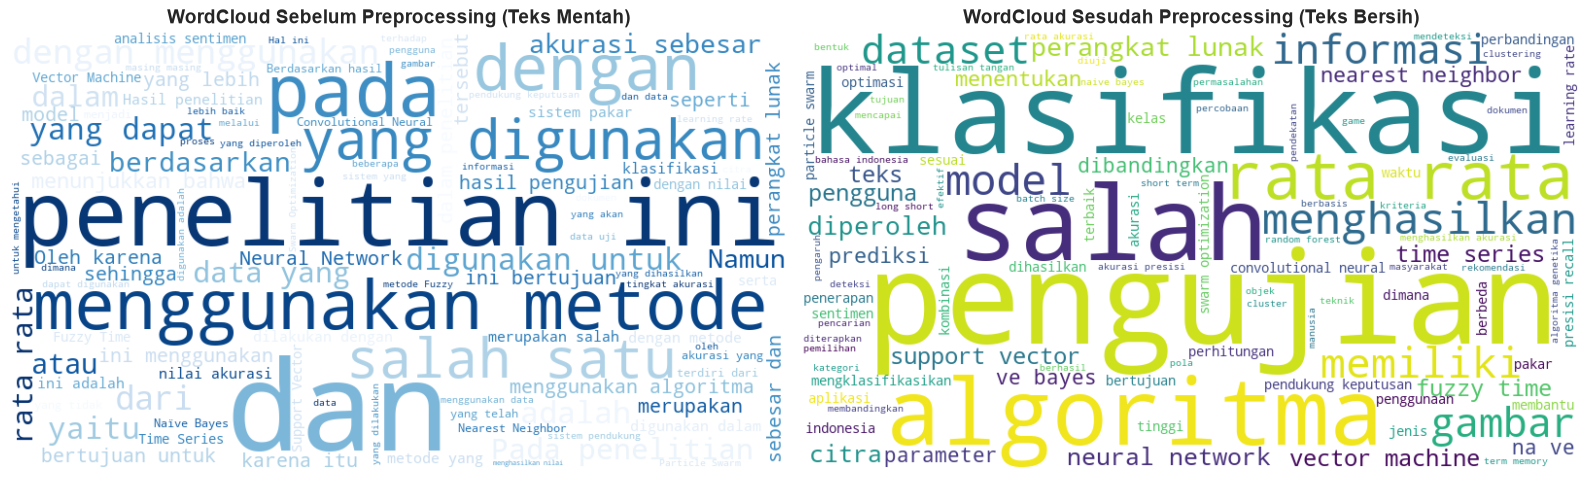

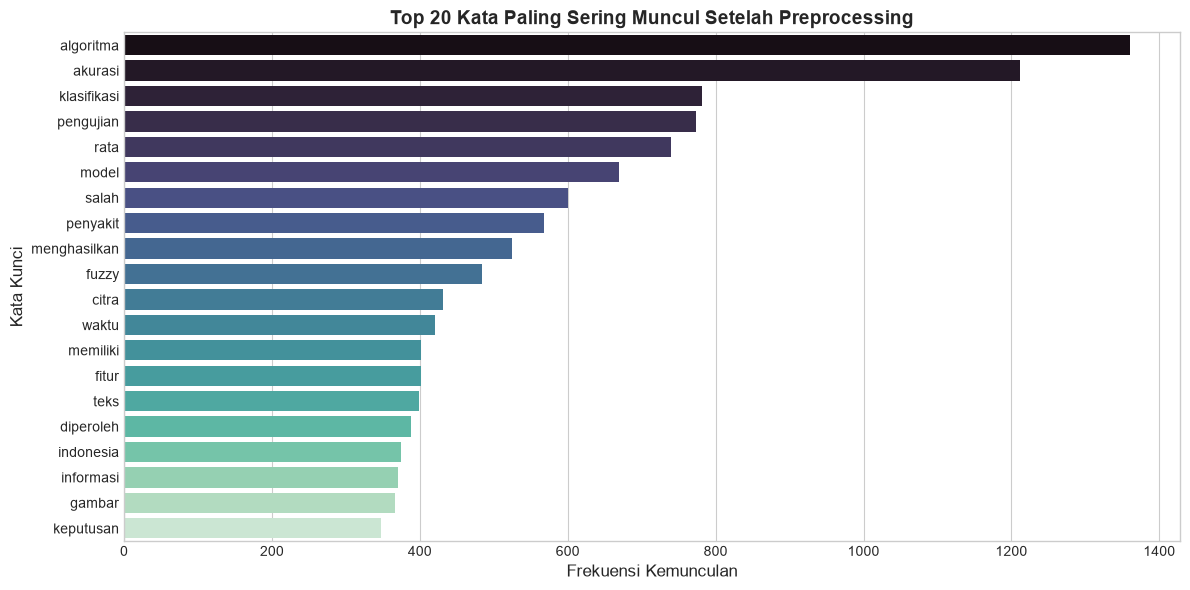

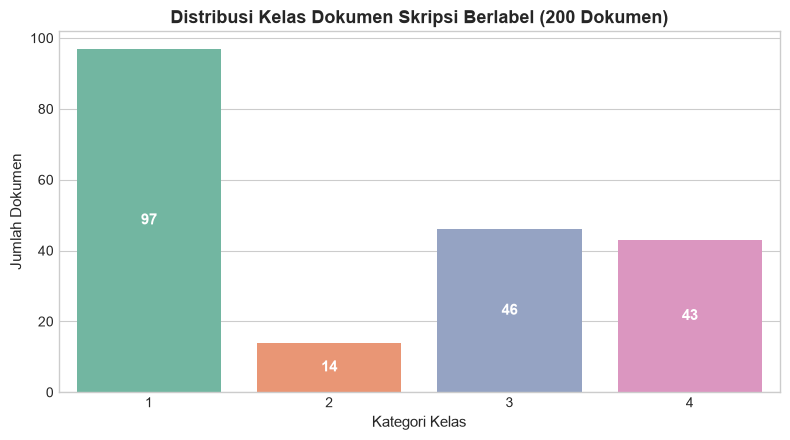

In [22]:
# 1. Komparasi WordCloud: Before vs After Preprocessing
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# WordCloud teks mentah (sebelum)
raw_text_corpus = " ".join(df["teks_lengkap"].dropna())
wc_raw = WordCloud(width=800, height=450, background_color="white", colormap="Blues", max_words=100).generate(raw_text_corpus)
axes[0].imshow(wc_raw, interpolation="bilinear")
axes[0].set_title("WordCloud Sebelum Preprocessing (Teks Mentah)", fontsize=14, fontweight="bold")
axes[0].axis("off")

# WordCloud teks bersih (sesudah)
clean_text_corpus = " ".join(df["teks_bersih"].dropna())
wc_clean = WordCloud(width=800, height=450, background_color="white", colormap="viridis", max_words=100).generate(clean_text_corpus)
axes[1].imshow(wc_clean, interpolation="bilinear")
axes[1].set_title("WordCloud Sesudah Preprocessing (Teks Bersih)", fontsize=14, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 2. Bar Chart: 20 Kata Paling Sering Muncul
all_tokens = [w for tokens in df["tokens_bersih"] for w in tokens]
word_counts = Counter(all_tokens).most_common(20)
words_df = pd.DataFrame(word_counts, columns=["Kata", "Frekuensi"])

plt.figure(figsize=(12, 6))
sns.barplot(data=words_df, x="Frekuensi", y="Kata", hue="Kata", palette="mako", legend=False)
plt.title("Top 20 Kata Paling Sering Muncul Setelah Preprocessing", fontsize=14, fontweight="bold")
plt.xlabel("Frekuensi Kemunculan", fontsize=12)
plt.ylabel("Kata Kunci", fontsize=12)
plt.tight_layout()
plt.show()

# 3. Bar Chart: Distribusi Kelas Berlabel
labeled_df = df.dropna(subset=["Kelas"]).copy()
labeled_df["Kelas"] = labeled_df["Kelas"].astype(int)

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=labeled_df, x="Kelas", hue="Kelas", palette="Set2", legend=False)
plt.title("Distribusi Kelas Dokumen Skripsi Berlabel (200 Dokumen)", fontsize=13, fontweight="bold")
plt.xlabel("Kategori Kelas", fontsize=11)
plt.ylabel("Jumlah Dokumen", fontsize=11)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Subword Tokenization: Eksplorasi WordPiece Tokenizer
*Mengacu pada notebook referensi dosen: `Contoh Wordpiece.ipynb`*

Tokenisasi kata biasa (`word-level`) punya kelemahan: kalau sebuah kata tidak ada di kosakata model, maka kata itu menjadi *out-of-vocabulary (OOV)* dan informasinya hilang. WordPiece mengatasi masalah ini dengan memecah kata menjadi sub-unit morfologis — misalnya kata `bioengineering` bisa dipecah menjadi `bio`, `##engine`, `##ering`.

Di sini kita demonstrasikan cara kerja WordPiece pada sampel kalimat abstrak skripsi, lalu hitung **Compression Ratio** untuk mengukur seberapa banyak kata dipecah menjadi subword.


In [23]:
# Inisialisasi BertTokenizer dengan vocabulary WordPiece pra-latih
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def demo_wordpiece(sentence: str):
    """Demonstrasi tokenisasi WordPiece per kata dan sub-kata."""
    print(f"Kalimat Input : {sentence}")
    tokens = tokenizer.tokenize(sentence)
    print(f"WordPiece Tokens ({len(tokens)} token): {tokens}")
    token_ids = tokenizer.convert_tokens_to_ids(tokens)
    print(f"Token IDs      : {token_ids}\n")
    
    print("Pemecahan Kata ke Subword:")
    for w in sentence.split():
        sub_tokens = tokenizer.tokenize(w)
        print(f"  '{w}' -> {sub_tokens}")

# Uji coba pada cuplikan abstrak skripsi mahasiswa
sample_abstract_sentence = "Algoritma bioengineering convolutional neural network mengoptimalkan klasifikasi smartphone"
print("=== DEMONSTRASI WORDPIECE TOKENIZATION ===")
demo_wordpiece(sample_abstract_sentence)


=== DEMONSTRASI WORDPIECE TOKENIZATION ===
Kalimat Input : Algoritma bioengineering convolutional neural network mengoptimalkan klasifikasi smartphone
WordPiece Tokens (26 token): ['al', '##gor', '##it', '##ma', 'bio', '##eng', '##ine', '##ering', 'con', '##vo', '##lu', '##tion', '##al', 'neural', 'network', 'meng', '##op', '##ti', '##mal', '##kan', 'k', '##las', '##if', '##ika', '##si', 'smartphone']
Token IDs      : [2632, 20255, 4183, 2863, 16012, 13159, 3170, 7999, 9530, 6767, 7630, 3508, 2389, 15756, 2897, 27955, 7361, 3775, 9067, 9126, 1047, 8523, 10128, 7556, 5332, 26381]

Pemecahan Kata ke Subword:
  'Algoritma' -> ['al', '##gor', '##it', '##ma']
  'bioengineering' -> ['bio', '##eng', '##ine', '##ering']
  'convolutional' -> ['con', '##vo', '##lu', '##tion', '##al']
  'neural' -> ['neural']
  'network' -> ['network']
  'mengoptimalkan' -> ['meng', '##op', '##ti', '##mal', '##kan']
  'klasifikasi' -> ['k', '##las', '##if', '##ika', '##si']
  'smartphone' -> ['smartphone']


### Perhitungan Rasio Kompresi (Compression Ratio)
Compression Ratio dihitung sebagai perbandingan jumlah token kata biasa dibagi jumlah token WordPiece. Nilai di bawah 1.0 berarti setiap kata rata-rata dipecah menjadi lebih dari satu subword token.


In [24]:
def compare_tokenization_methods(texts):
    """Membandingkan jumlah token dan rasio kompresi Word-level vs WordPiece."""
    total_word_count = 0
    total_wordpiece_count = 0
    unique_word_tokens = set()
    unique_wordpiece_tokens = set()
    
    for text in texts:
        words = text.lower().split()
        unique_word_tokens.update(words)
        total_word_count += len(words)
        
        wp_tokens = tokenizer.tokenize(text)
        unique_wordpiece_tokens.update(wp_tokens)
        total_wordpiece_count += len(wp_tokens)
        
    compression_ratio = total_word_count / total_wordpiece_count
    
    return {
        "Total Word Tokens": total_word_count,
        "Total WordPiece Tokens": total_wordpiece_count,
        "Unique Word Tokens": len(unique_word_tokens),
        "Unique WordPiece Tokens": len(unique_wordpiece_tokens),
        "Compression Ratio": round(compression_ratio, 3)
    }

sample_titles = [
    "Klasifikasi kecenderungan tingkat depresi mahasiswa menggunakan machine learning",
    "Secure chatting menggunakan algoritma AES dan blockchain berbasis mobile",
    "Peringkasan teks Bahasa Indonesia pada cerpen menggunakan metode latent semantic analysis",
    "Pengenalan angka tulisan tangan berorientasi menggunakan convolutional neural network"
]

comp_results = compare_tokenization_methods(sample_titles)
print("=== PERBANDINGAN METODE TOKENISASI (WORD-LEVEL VS WORDPIECE) ===")
for k, v in comp_results.items():
    print(f"{k:<26}: {v}")

print(f"\nInterpretasi: Setiap 1 kata rata-rata dipecah menjadi {1/comp_results['Compression Ratio']:.2f} token WordPiece.")



=== PERBANDINGAN METODE TOKENISASI (WORD-LEVEL VS WORDPIECE) ===
Total Word Tokens         : 37
Total WordPiece Tokens    : 93
Unique Word Tokens        : 34
Unique WordPiece Tokens   : 75
Compression Ratio         : 0.398

Interpretasi: Setiap 1 kata rata-rata dipecah menjadi 2.51 token WordPiece.
